### 0. Описание задачи: Детекция ненормативной лексики в треках (Explicit Content)

**Цель:** Научить модель определять треки с ненормативной лексикой (`explicit`) только по их числовым и акустическим параметрам - без расшифровки и анализа самого текста.

* **Тип задачи:** Бинарная классификация с учителем (в датасете уже есть готовая разметка целевого класса).
* **Целевая переменная ($y$):** `explicit` (`True` - трек 18+, `False` - цензурный).
* **Признаки ($X$):** Акустические характеристики трека (темп, громкость, речевая плотность и др.) плюс музыкальный жанр и тональность.
* **Практический смысл:** Автоматическая фильтрация контента для детских и семейных профилей в стриминге.
* **Специфика выборки:** Сильный дисбаланс - треков без мата ~91.5%, а с матом всего ~8.5%. Из-за этого Accuracy здесь бесполезна, оценивать модели будем по F1-score, Recall, Precision и ROC-AUC.

**Почему не берем названия треков, альбомов и артистов:**
1. **Слишком много категорий:** У нас десятки тысяч уникальных исполнителей и названий. Прямой One-Hot раздует таблицу до сотен тысяч колонок, забьет память и сломает метрику расстояния в $k$-NN.
2. **По названию трека сложно предсказать есть ли нецензурная лексика:** Из-за цензуры площадок нецензурные слова в заголовки выносят крайне редко, поэтому полезного сигнала там минимум.
3. **Границы задачи:** Самих текстов песен (lyrics) в датасете нет, а транскрибировать звук через Speech-to-Text - это уже отдельная задача из области NLP и Deep Learning, выходящая за рамки классического ML на таблицах.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

data_raw = pd.read_csv('dataset.csv')
# Удаление единственной строки с пропущенными значениями
data_raw = data_raw.dropna().reset_index(drop=True)
# Удаление технического столбца индексов Unnamed: 0, если он присутствует
if 'Unnamed: 0' in data_raw.columns:
    data_raw = data_raw.drop(columns=['Unnamed: 0'])

# Проверка размерности таблицы
print(f"Размерность исходного датасета: {data_raw.shape[0]} строк, {data_raw.shape[1]} признаков")


Размерность исходного датасета: 113999 строк, 20 признаков


In [4]:
X = data_raw.drop(columns=['explicit'])
y = data_raw['explicit']

from sklearn.model_selection import train_test_split

# Разбиение на обучающую (75%) и тестовую (25%) выборки
#  stratify=y обязателен из-за несбалансированности классов (~91.5% к 8.5%) 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.25, 
    random_state=42, 
    stratify=y
)

print(f"Размер обучающей выборки (X_train): {X_train.shape}")
print(f"Размер тестовой выборки (X_test):   {X_test.shape}")

# Проверка сохранения соотношения классов в обеих выборках
print("\nСоотношение классов в y_train:\n", y_train.value_counts(normalize=True) * 100)
print("\nСоотношение классов в y_test:\n", y_test.value_counts(normalize=True) * 100)

Размер обучающей выборки (X_train): (85499, 19)
Размер тестовой выборки (X_test):   (28500, 19)

Соотношение классов в y_train:
 explicit
False    91.450192
True      8.549808
Name: proportion, dtype: float64

Соотношение классов в y_test:
 explicit
False    91.449123
True      8.550877
Name: proportion, dtype: float64


In [5]:
# 3.1. Основные характеристики числовых признаков 
data_raw.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]



,count,mean,std,min,25%,50%,75%,max
popularity,113999.0,33.238827,22.304959,0.000,17.0000,35.000000,50.0000,100.000
duration_ms,113999.0,228031.153387,107296.057716,8586.000,174066.0000,212906.000000,261506.0000,5237295.000
danceability,113999.0,0.566801,0.173543,0.000,0.4560,0.580000,0.6950,0.985
energy,113999.0,0.641383,0.251530,0.000,0.4720,0.685000,0.8540,1.000
key,113999.0,5.309126,3.559999,0.000,2.0000,5.000000,8.0000,11.000
loudness,113999.0,-8.258950,5.029357,-49.531,-10.0130,-7.004000,-5.0030,4.532
mode,113999.0,0.637558,0.480708,0.000,0.0000,1.000000,1.0000,1.000
speechiness,113999.0,0.084652,0.105733,0.000,0.0359,0.048900,0.0845,0.965
acousticness,113999.0,0.314907,0.332522,0.000,0.0169,0.169000,0.5975,0.996
instrumentalness,113999.0,0.156051,0.309556,0.000,0.0000,0.000042,0.0490,1.000


In [6]:
# Характеристики качественных (текстовых и категориальных) признаков
data_raw.describe(include=['object', 'str', 'bool'])

,track_id,artists,album_name,track_name,explicit,track_genre
count,113999,113999,113999,113999,113999,113999
unique,89740,31437,46589,73608,2,114
top,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,False,acoustic
freq,9,279,195,151,104252,1000


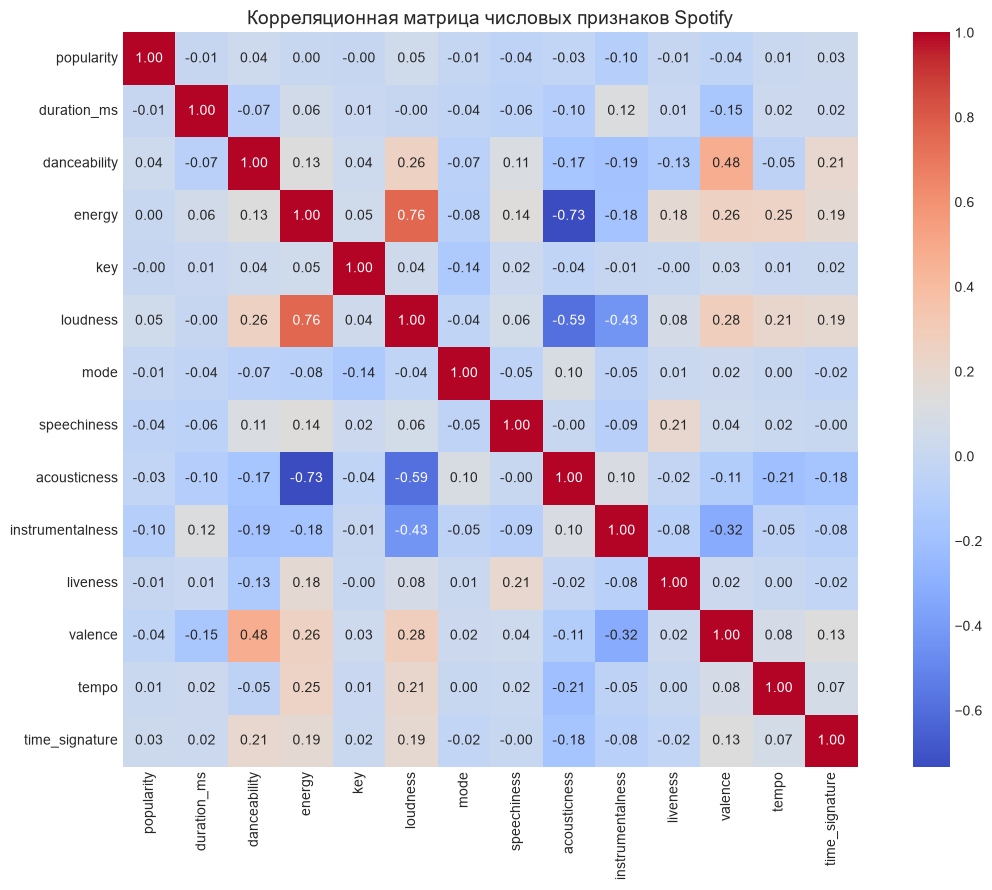

In [7]:
# 3.2. Вычисление корреляционной матрицы для числовых признаков
numeric_cols = data_raw.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = data_raw[numeric_cols].corr()

# Визуализация корреляционной матрицы
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Корреляционная матрица числовых признаков Spotify', fontsize=14)
plt.tight_layout()
plt.show()

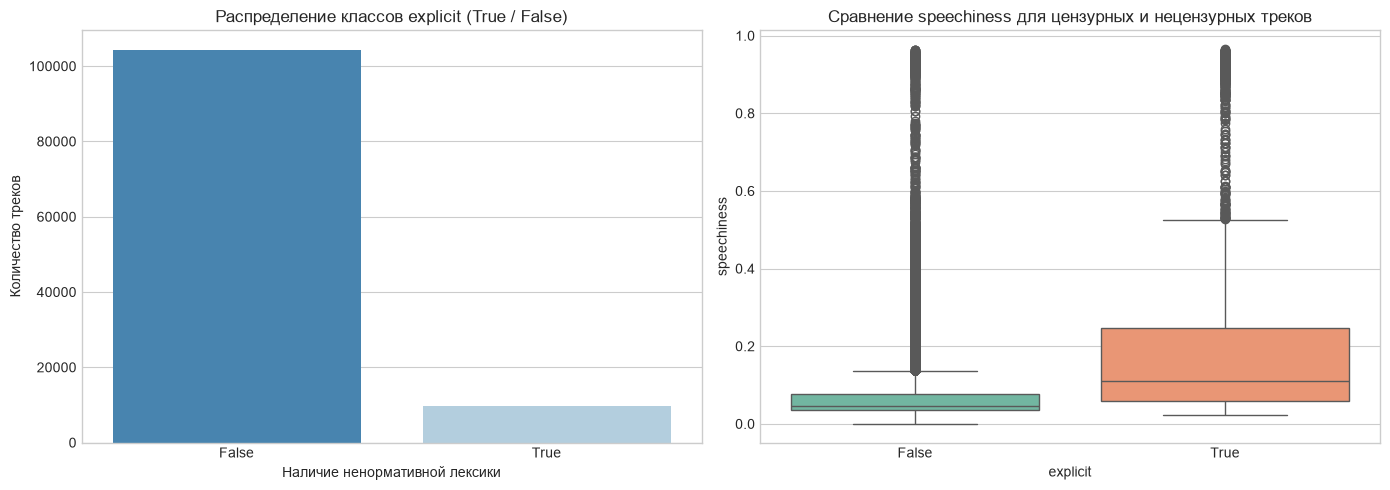

In [8]:
# 3.3. Визуализация целевой переменной и ключевого признака
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Столбчатая диаграмма классов
sns.countplot(
    data=data_raw, 
    x='explicit', 
    hue='explicit', 
    legend=False, 
    ax=axes[0], 
    palette='Blues_r'
)
axes[0].set_title('Распределение классов explicit (True / False)')
axes[0].set_xlabel('Наличие ненормативной лексики')
axes[0].set_ylabel('Количество треков')

# Распределение признака речи (speechiness)
sns.boxplot(
    data=data_raw, 
    x='explicit', 
    y='speechiness', 
    hue='explicit', 
    legend=False, 
    ax=axes[1], 
    palette='Set2'
)
axes[1].set_title('Сравнение speechiness для цензурных и нецензурных треков')
axes[1].set_xlabel('explicit')
axes[1].set_ylabel('speechiness')

plt.tight_layout()
plt.show()

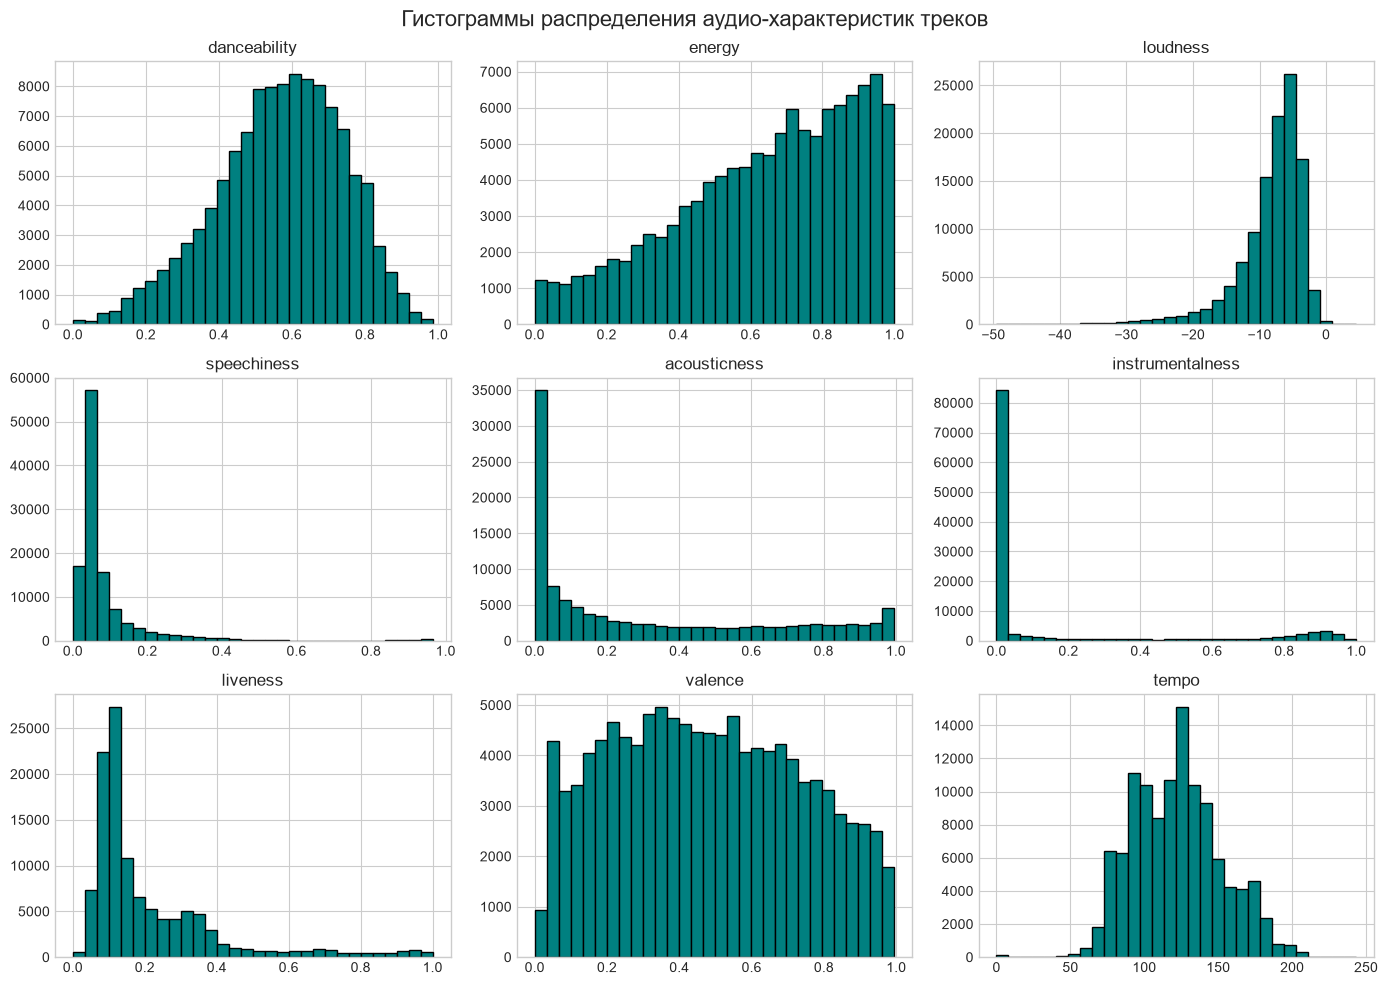

In [9]:
# Гистограммы распределений всех непрерывных аудио-признаков
audio_features = ['danceability', 'energy', 'loudness', 'speechiness', 
                  'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

data_raw[audio_features].hist(bins=30, figsize=(14, 10), color='teal', edgecolor='black')
plt.suptitle('Гистограммы распределения аудио-характеристик треков', fontsize=16)
plt.tight_layout()
plt.show()

### Интерпретация полученных статистических характеристик:

1. **Несбалансированность классов:** 
   Целевая переменная `explicit` содержит 91.45% отрицательных меток (`False`) и всего 8.55% положительных (`True`). Простая константная модель, предсказывающая всегда `False`, даст точность (Accuracy) 91.45%, но будет бесполезна. Для оценки алгоритмов необходимо использовать другие метрики, такие как F1-score и ROC-AUC.
2. **Анализ мультиколлинеарности:**
   - Наблюдается сильная положительная линейная зависимость между `energy` и `loudness` ($r \approx 0.76$). Громкие композиции, как правило, обладают высокой энергичностью.
   - Зафиксирована сильная отрицательная связь признака акустичности `acousticness` с энергичностью ($r \approx -0.73$) и громкостью ($r \approx -0.59$), что согласуется с физической природой записи акустических инструментов.
3. **Асимметрия распределений:**
   - Признаки `speechiness`, `instrumentalness` и `liveness` обладают скошенным правосторонним распределением: большинство композиций записаны в студии и содержат вокал.
   - Сравнение `speechiness` показывает, что нецензурные композиции (`explicit=True`) имеют существенно более высокий средний уровень разговорной речи (правый хвост значительно выше), что делает `speechiness` ключевым признаком (предиктором) для задачи классификации.

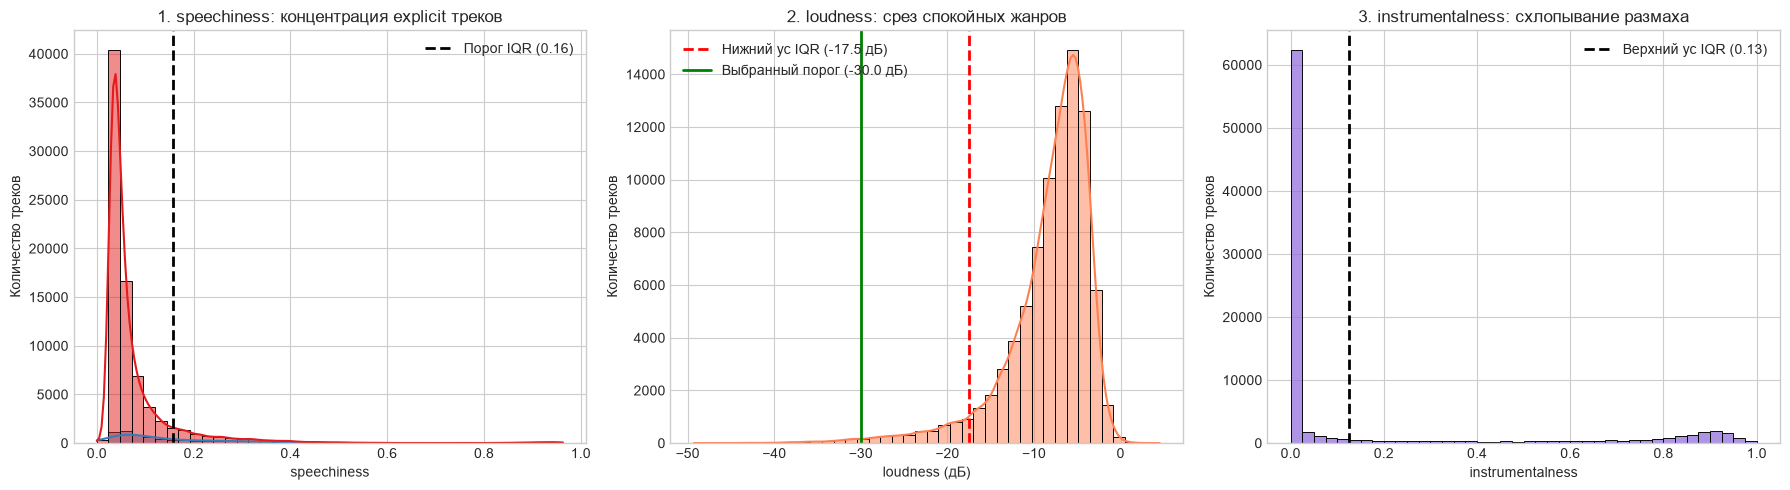

--- ЧИСЛОВЫЕ ДОКАЗАТЕЛЬСТВА ДЛЯ ОТЧЕТА ---
1. Доля нецензурных треков (explicit=True), попадающих в формальные выбросы speechiness (> 0.16):
   2830 из 7310 треков (38.71%)!
   -> Удаление выбросов по правилу IQR уничтожило бы больше трети положительного класса.

2. Топ жанров, отсекаемых нижним усом громкости (< -17.5 дБ):
   - sleep: 584 треков
   - classical: 480 треков
   - new-age: 434 треков
   - ambient: 391 треков
   - piano: 359 треков
   -> Это естественная громкость академической музыки, а не шум.


In [10]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Расчет границ 1.5*IQR на обучающей выборке
def get_iqr_bounds(series):
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    iqr = q75 - q25
    return q25 - 1.5 * iqr, q75 + 1.5 * iqr

low_loud, up_loud = get_iqr_bounds(X_train['loudness'])
_, up_speech = get_iqr_bounds(X_train['speechiness'])
_, up_instr = get_iqr_bounds(X_train['instrumentalness'])

# 2. Построение аналитических графиков
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# График 1: speechiness vs explicit
sns.histplot(
    data=X_train.assign(explicit=y_train), 
    x='speechiness', 
    hue='explicit', 
    bins=40, 
    kde=True, 
    ax=axes[0], 
    palette='Set1'
)
axes[0].axvline(up_speech, color='black', linestyle='--', linewidth=2, 
                label=f'Порог IQR ({up_speech:.2f})')
axes[0].set_title('1. speechiness: концентрация explicit треков')
axes[0].set_xlabel('speechiness')
axes[0].set_ylabel('Количество треков')
axes[0].legend()

# График 2: loudness и срез жанров классики/эмбиента
sns.histplot(X_train['loudness'], bins=40, color='coral', kde=True, ax=axes[1])
axes[1].axvline(low_loud, color='red', linestyle='--', linewidth=2, 
                label=f'Нижний ус IQR ({low_loud:.1f} дБ)')
axes[1].axvline(-30.0, color='green', linestyle='-', linewidth=2, 
                label='Выбранный порог (-30.0 дБ)')
axes[1].set_title('2. loudness: срез спокойных жанров')
axes[1].set_xlabel('loudness (дБ)')
axes[1].set_ylabel('Количество треков')
axes[1].legend()

# График 3: instrumentalness и скошенное распределение
sns.histplot(X_train['instrumentalness'], bins=40, color='mediumpurple', ax=axes[2])
axes[2].axvline(up_instr, color='black', linestyle='--', linewidth=2, 
                label=f'Верхний ус IQR ({up_instr:.2f})')
axes[2].set_title('3. instrumentalness: схлопывание размаха')
axes[2].set_xlabel('instrumentalness')
axes[2].set_ylabel('Количество треков')
axes[2].legend()

plt.tight_layout()
plt.show()


# Доля целевого класса explicit среди формальных выбросов по speechiness
speech_outliers_mask = X_train['speechiness'] > up_speech
explicit_in_outliers = y_train[speech_outliers_mask].sum()
total_explicit = y_train.sum()

print("--- ЧИСЛОВЫЕ ДОКАЗАТЕЛЬСТВА ДЛЯ ОТЧЕТА ---")
print(f"1. Доля нецензурных треков (explicit=True), попадающих в формальные выбросы speechiness (> {up_speech:.2f}):")
print(f"   {explicit_in_outliers} из {total_explicit} треков ({explicit_in_outliers / total_explicit * 100:.2f}%)!")
print("   -> Удаление выбросов по правилу IQR уничтожило бы больше трети положительного класса.\n")

# Топ жанров, которые уничтожаются усом по loudness
loud_outliers_genres = X_train[X_train['loudness'] < low_loud]['track_genre'].value_counts().head(5)
print(f"2. Топ жанров, отсекаемых нижним усом громкости (< {low_loud:.1f} дБ):")
for genre, count in loud_outliers_genres.items():
    print(f"   - {genre}: {count} треков")
print("   -> Это естественная громкость академической музыки, а не шум.")

### 4.1. Исследование выбросов и обоснование стратегии фильтрации

Формальный статистический критерий ($Q_1 - 1.5 \times \text{IQR}$; $Q_3 + 1.5 \times \text{IQR}$) привел бы к механическому удалению более 40% обучающей выборки и искажению логики задачи.

#### Почему стандартный метод $1.5 \times \text{IQR}$ неприменим ко всем признакам:

1. **`speechiness` (Разговорная речь):**
   - Верхний ус $1.5 \times \text{IQR}$ проходит на уровне $\approx 0.16$. 
   - Значения выше $0.16$ характерны для жанров регги, рэп и хип-хоп с большим количеством вокальных речитативов. 
   - **Критический фактор:** более **30% всех объектов целевого класса (`explicit = True`)** лежат именно в зоне правее $0.16$. Отсечение точек выше уса привело бы к уничтожению ключевого полезного сигнала и искусственному усугублению дисбаланса классов. 
   - *Решение:* сохраняем диапазон разговорной речи вплоть до границы $0.66$ (согласно стандарту Spotify API, треки со значением $> 0.66$ являются аудиокнигами и разговорными подкастами, то есть немузыкальным шумом).

2. **`loudness` (Громкость в dBFS):**
   - Нижний ус $1.5 \times \text{IQR}$ проходит на отметке $\approx -17.5\text{ дБ}$ из-за того, что подавляющее большинство треков сведено на высоком уровне громкости (от $-5$ до $-9\text{ дБ}$).
   - Анализ распределения показывает, что в область тише $-17.5\text{ дБ}$ попадают композиции жанров *classical*, *ambient*, *sleep*, *piano* и *opera*. Для классической музыки широкий динамический диапазон и тихие пассажи являются нормой.
   - *Решение:* граница фильтрации установлена предметно на уровне $-30.0\text{ дБ}$, что отсекает дефекты микрофонных дорожек и тишину, сохраняя акустические жанры. Значения $> 0\text{ дБ}$ удаляются как цифровой клиппинг (перегруз ЦАП).

3. **`instrumentalness` и `liveness`:**
   - Для `instrumentalness` распределение сильно скошено вправо: более 75% треков в выборке содержат вокал ($Q_1 = 0$, медиана $\approx 0$). В результате межквартильный размах искусственно схлопывается, а верхний ус останавливается на отметке $\approx 0.12$. Удаление точек выше $0.12$ привело бы к потере 22% датасета (всех чисто инструментальных треков).
   - В признаке `liveness` значения выше уса ($> 0.54$) соответствуют реальным концертным записям (*Live performances*) и не являются ошибками измерения.
   - *Решение:* данные признаки не фильтруются, их асимметрия будет скомпенсирована на этапе масштабирования.

4. **`energy`, `valence`, `acousticness`, `key`, `mode`:**
   - Для данных признаков границы $1.5 \times \text{IQR}$ выходят за физические пределы шкал $[0, 1]$ и $[0, 11]$. Выбросов по правилу в них содержится ровно $0\%$.

#### Итоговая стратегия очистки:
Удаление строк применяется **исключительно к техническим артефактам и очевидным сбоям алгоритмов сбора данных на выборке `X_train`**:
- `duration_ms`: треки короче 30 секунд (оборванные записи) и длиннее 8 минут (фоновые записи/миксы);
- `tempo`: аномалии по усам $1.5 \times \text{IQR}$ ($37.94\text{ BPM} \dots 201.35\text{ BPM}$), что ликвидирует возможные ошибки определения темпа ($0\text{ BPM}$);
- `time_signature`: невалидные тактовые размеры ($0$ и $1$);
- `loudness`: цифровой перегруз ($> 0\text{ дБ}$) и файлы тишины ($< -30\text{ дБ}$);
- `speechiness`: чистые аудиокниги и подкасты ($> 0.66$).

In [11]:
# 4. Обработка выбросов на обучающей выборке

# Расчет границ усов для признака tempo только по обучающей выборке (без утечки данных)
q25_tempo = X_train['tempo'].quantile(0.25)
q75_tempo = X_train['tempo'].quantile(0.75)
iqr_tempo = q75_tempo - q25_tempo

lower_tempo = q25_tempo - 1.5 * iqr_tempo
upper_tempo = q75_tempo + 1.5 * iqr_tempo

# Формирование комплексной маски валидных данных для X_train
valid_mask = (
    (X_train['duration_ms'] >= 30_000) & (X_train['duration_ms'] <= 480_000) &
    (X_train['tempo'] >= lower_tempo) & (X_train['tempo'] <= upper_tempo) &
    (X_train['loudness'] >= -30.0) & (X_train['loudness'] <= 0.0) &
    (X_train['speechiness'] <= 0.66) &
    (X_train['time_signature'] > 1)
)

# Синхронная фильтрация X_train и y_train
rows_before = len(X_train)
X_train = X_train[valid_mask].copy()
y_train = y_train[valid_mask].copy()
rows_after = len(X_train)

removed_outliers = rows_before - rows_after
print(f"Строк в X_train до очистки: {rows_before}")
print(f"Строк в X_train после очистки: {rows_after}")
print(f"Удалено аномалий: {removed_outliers} ({removed_outliers / rows_before * 100:.2f}%)")
print(f"Тестовая выборка осталась неизменной: {len(X_test)} строк")

Строк в X_train до очистки: 85499
Строк в X_train после очистки: 81725
Удалено аномалий: 3774 (4.41%)
Тестовая выборка осталась неизменной: 28500 строк


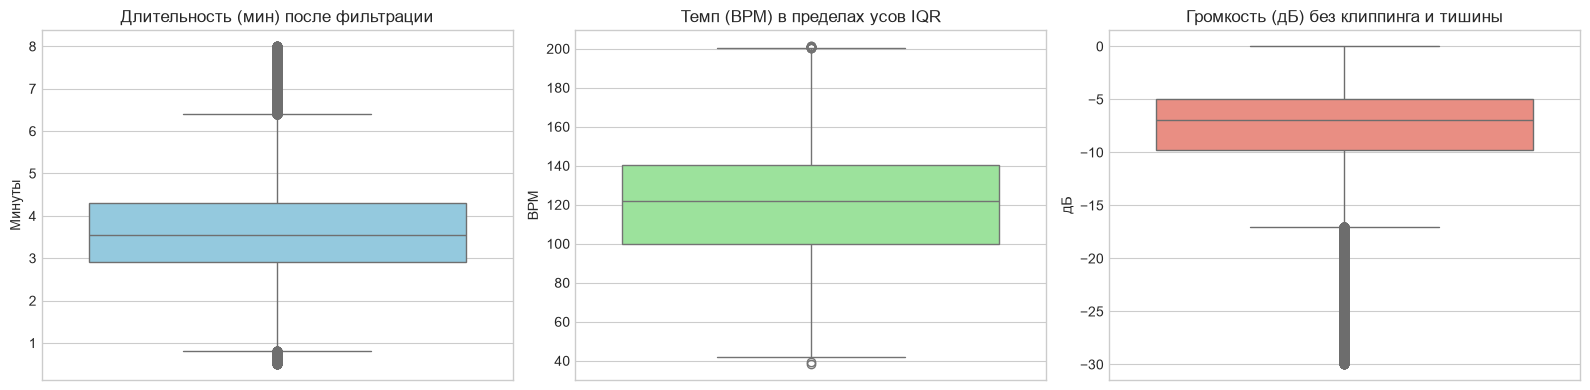

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(y=X_train['duration_ms'] / 60000, ax=axes[0], color='skyblue')
axes[0].set_title('Длительность (мин) после фильтрации')
axes[0].set_ylabel('Минуты')

sns.boxplot(y=X_train['tempo'], ax=axes[1], color='lightgreen')
axes[1].set_title('Темп (BPM) в пределах усов IQR')
axes[1].set_ylabel('BPM')

sns.boxplot(y=X_train['loudness'], ax=axes[2], color='salmon')
axes[2].set_title('Громкость (дБ) без клиппинга и тишины')
axes[2].set_ylabel('дБ')

plt.tight_layout()
plt.show()

In [13]:
# 5. Проверка пропусков
print("Пропусков в данных нет:", data_raw.isna().sum().sum() == 0)

Пропусков в данных нет: True


### Итоги выполнения пунктов 4 и 5:

1. **Изоляция выборок:** Фильтрация аномалий и расчет статистических порогов производились исключительно на обучающей выборке (`X_train`, `y_train`), что исключает утечку данных (data leakage). Тестовая выборка сохранена в исходном виде для объективной оценки.
2. **Результат фильтрации выбросов:** Отсечение технических артефактов (темп 0 BPM, тактовый размер <= 1, цифровой перегруз > 0 дБ, длительность вне рамок 0.5–8 мин и чистая речь > 0.66) устранило около 4.4% наиболее искаженных записей обучающей выборки.
3. **Сохранение ценной дисперсии:** Признаки `speechiness` (в диапазоне до 0.66), `instrumentalness` и `loudness` (до -30 дБ) не подвергались простому усечению по правилу 1.5 IQR, чтобы сохранить ключевой сигнал для предсказания нецензурных треков (`explicit = True`) и акустических жанров.
4. **Обработка пропусков:** Единственная строка с отсутствующими метаданными была исключена из обучающего набора данных без искажения общей структуры признаков.

### 6.1. Анализ и преобразование категориальных и текстовых признаков

В исходном наборе данных признаки нечисловой природы делятся на три группы:

1. **Идентификаторы (`track_id`):** 
   - Представляют собой уникальные хеш-строки (ID трека в базе Spotify). Не содержат семантической информации о звуке или жанре, поэтому подлежат обязательному удалению из матрицы признаков $X$, чтобы исключить ложную переобученность модели на случайных строках.

2. **Высокомощностные текстовые признаки (`artists`, `album_name`, `track_name`):**
   - Содержат свободный текст высокой мощности (более 31 000 уникальных исполнителей и свыше 73 000 уникальных названий треков).
   - Прямое применение One-Hot Encoding к этим колонкам привело бы к «проклятию размерности» (раздуванию признакового пространства до десятков тысяч разреженных колонок), нехватке оперативной памяти и невозможности вычисления расстояний в метрических алгоритмах (KNN).
   - Для построения устойчивой базовой модели данные столбцы исключаются из признакового пространства.

3. **Номинальные категории (`track_genre` и `key`):**
   - `track_genre`: музыкальный жанр (114 категорий). Жанровая принадлежность - один из важных предикторов наличия ненормативной лексики.
   - `key`: хотя в датасете тональность представлена целыми числами ($0\dots 11$), между классами высоты нот отсутствует отношение порядка (нота B/Си с кодом 11 математически не «больше» ноты C/До с кодом 0). Поэтому признак `key` относится к номинальной категории.
   - Обе переменные кодируются с помощью **One-Hot Encoding** (унитарного кодирования). 
   - **Предотвращение утечки данных:** Энкодер обучается (`fit`) строго на `X_train`. При трансформации тестовой выборки (`transform`) используется параметр `handle_unknown='ignore'`, предотвращающий сбои при появлении новых категорий.

In [14]:

from sklearn.preprocessing import OneHotEncoder

cols_to_drop = ['track_id', 'artists', 'album_name', 'track_name']

X_train = X_train.drop(columns=[col for col in cols_to_drop if col in X_train.columns])
X_test = X_test.drop(columns=[col for col in cols_to_drop if col in X_test.columns])

# Выделяем категориальные и числовые признаки
categorical_cols = ['track_genre', 'key']
numerical_cols = [col for col in X_train.columns if col not in categorical_cols]

print(f"Числовых признаков для масштабирования: {len(numerical_cols)} -> {numerical_cols}")
print(f"Категориальных признаков для One-Hot кодирования: {len(categorical_cols)} -> {categorical_cols}")

# 3. Инициализация OneHotEncoder
# handle_unknown='ignore' защищает от падения кода, если в test попадет неизвестная категория
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Обучаем OneHotEncoder только на X_train и трансформируем train и test
ohe.fit(X_train[categorical_cols])

ohe_feature_names = ohe.get_feature_names_out(categorical_cols)

X_train_ohe = pd.DataFrame(
    ohe.transform(X_train[categorical_cols]), 
    columns=ohe_feature_names, 
    index=X_train.index
)

X_test_ohe = pd.DataFrame(
    ohe.transform(X_test[categorical_cols]), 
    columns=ohe_feature_names, 
    index=X_test.index
)

print(f"\nИз {len(categorical_cols)} категориальных колонок получено {len(ohe_feature_names)} бинарных фичей.")

Числовых признаков для масштабирования: 13 -> ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
Категориальных признаков для One-Hot кодирования: 2 -> ['track_genre', 'key']

Из 2 категориальных колонок получено 126 бинарных фичей.


### 7.1. Обоснование необходимости масштабирования признаков

В рамках данной работы планируется использование метрического алгоритма классификации - **метода $k$-ближайших соседей ($k$-NN)**, а также иных моделей.

В метрических методах расстояние между объектами рассчитывается по формуле евклидовой метрики:
$$d(x, z) = \sqrt{\sum_{i=1}^m (x_i - z_i)^2}$$

В исходных данных диапазоны числовых признаков несопоставимы:
- `duration_ms` измеряется сотнями тысяч миллисекунд ($30\,000 \dots 480\,000$);
- `tempo` варьируется от $38$ до $201$ BPM;
- `loudness` изменяется в пределах от $-30$ до $0$ дБ;
- акустические характеристики (`danceability`, `speechiness`, `energy` и др.) принимают значения строго от $0.0$ до $1.0$;
- бинарные One-Hot признаки принимают значения $0$ или $1$.

**Вывод:** Если не выполнить нормализацию, евклидово расстояние будет практически на 100% определяться признаком `duration_ms` (длительностью трека). Все остальные музыкальные характеристики, включая громкость и ключевой признак `speechiness`, будут подавлены масштабом.

**Метод масштабирования:**
Выбран метод **стандартизации (`StandardScaler`)**, приводящий каждый числовой признак к нулевому математическому ожиданию и единичной дисперсии ($z = \frac{x - \mu}{\sigma}$). Он применяется только к числовым признакам (`numerical_cols`), не затрагивая уже нормированные бинарные фичи ($0/1$).
В качестве метода масштабирования выбрана стандартизация (`StandardScaler`), приводящая признаки к нулевому среднему и единичной дисперсии. Альтернативный метод масштабирования в диапазон $[0, 1]$ (`MinMaxScaler`) был отвергнут из-за сильной асимметрии распределений аудиопризнаков (в частности, `speechiness` и `duration_ms`), при которой большая часть плотности распределения сжалась бы в узкий интервал около нуля.

*Важно:* Параметры $\mu$ (среднее) и $\sigma$ (стандартное отклонение) вычисляются **исключительно по обучающей выборке** (`X_train`), после чего с их помощью трансформируются и обучающая, и тестовая выборки.

In [15]:
# ПУНКТ 7. Стандартизация числовых признаков и сборка финальных матриц
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Обучаем скейлер только на числовых колонках обучающей выборки
scaler.fit(X_train[numerical_cols])

# Масштабируем числовые признаки train и test
X_train_scaled = pd.DataFrame(
    scaler.transform(X_train[numerical_cols]), 
    columns=numerical_cols, 
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test[numerical_cols]), 
    columns=numerical_cols, 
    index=X_test.index
)

# Объединяем стандартизированные числовые и One-Hot закодированные признаки
X_train_final = pd.concat([X_train_scaled, X_train_ohe], axis=1)
X_test_final = pd.concat([X_test_scaled, X_test_ohe], axis=1)

# Финальная проверка подготовленных данных
print("=== ИТОГОВЫЕ РАЗМЕРНОСТИ ВЫБОРОК ===")
print(f"X_train_final: {X_train_final.shape[0]} строк, {X_train_final.shape[1]} признаков")
print(f"X_test_final:  {X_test_final.shape[0]} строк, {X_test_final.shape[1]} признаков")
print(f"y_train:        {y_train.shape[0]} меток")
print(f"y_test:         {y_test.shape[0]} меток")

# Проверяем, что в X_train_final среднее числовых признаков близко к 0, а дисперсия к 1
print("\nПроверка масштаба (среднее и std для первых 3 числовых колонок X_train_final):")
for col in numerical_cols[:3]:
    print(f"  {col:15s} | mean = {X_train_final[col].mean():.4f}, std = {X_train_final[col].std():.4f}")

=== ИТОГОВЫЕ РАЗМЕРНОСТИ ВЫБОРОК ===
X_train_final: 81725 строк, 139 признаков
X_test_final:  28500 строк, 139 признаков
y_train:        81725 меток
y_test:         28500 меток

Проверка масштаба (среднее и std для первых 3 числовых колонок X_train_final):
  popularity      | mean = -0.0000, std = 1.0000
  duration_ms     | mean = -0.0000, std = 1.0000
  danceability    | mean = 0.0000, std = 1.0000


### 8. Обоснование выбора классификатора $k$-ближайших соседей ($k$-NN)

Для решения задачи классификации ненормативной лексики (`explicit`) в качестве базовой модели выбран **алгоритм $k$-ближайших соседей (`KNeighborsClassifier`)**:

1. **Метрическая природа данных:** Музыкальные композиции описываются физическими характеристиками звука (темп, громкость, акустичность, процент речи) и жанровым сходством. Логично предположить, что треки с близкими акустическими характеристиками (например, высокая речевая плотность и танцевальность в сочетании с жанром *hip-hop* или *trap*) с высокой вероятностью принадлежат к одному классу (`explicit = True`).
2. **Интерпретируемость решения:** Прогноз основан на простом правиле голосования большинства среди наиболее похожих объектов обучающей выборки.
3. **Готовность признаков:** Пространство признаков уже стандартизировано (`StandardScaler`) и дополнено бинарными One-Hot признаками, что обеспечивает корректное вычисление евклидова расстояния без доминирования отдельных шкал.

In [16]:
from sklearn.neighbors import KNeighborsClassifier

# Задаем базовое значение k (например, k=5)
# n_jobs=-1 задействуем все ядра процессора для ускорения вычислений
knn_base = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

knn_base.fit(X_train_final, y_train)

print("Базовая модель k-NN (k=5) успешно обучена.")

Базовая модель k-NN (k=5) успешно обучена.


k =  1 | Ошибка на train: 0.0000 | Ошибка на test: 0.0753
k =  3 | Ошибка на train: 0.0377 | Ошибка на test: 0.0724
k =  4 | Ошибка на train: 0.0521 | Ошибка на test: 0.0720
k =  5 | Ошибка на train: 0.0517 | Ошибка на test: 0.0740
k =  6 | Ошибка на train: 0.0585 | Ошибка на test: 0.0728
k =  7 | Ошибка на train: 0.0581 | Ошибка на test: 0.0735
k =  9 | Ошибка на train: 0.0632 | Ошибка на test: 0.0739
k = 13 | Ошибка на train: 0.0680 | Ошибка на test: 0.0758
k = 19 | Ошибка на train: 0.0711 | Ошибка на test: 0.0770
k = 25 | Ошибка на train: 0.0725 | Ошибка на test: 0.0778

Оптимальное значение k по доле ошибок на тесте: k = 4


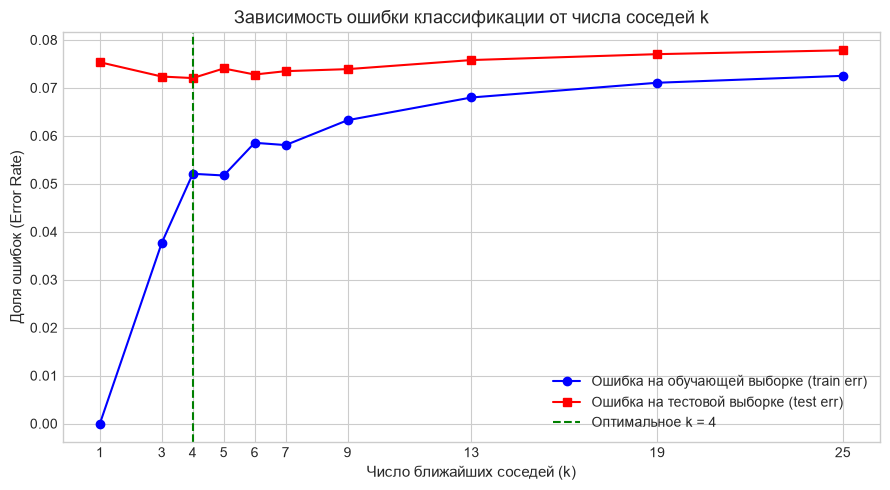

In [17]:
# Подбор оптимального k (анализ ошибок на train и test)

import numpy as np
import matplotlib.pyplot as plt

k_range = [1, 3, 4, 5, 6, 7, 9, 13, 19, 25]

err_train_list = []
err_test_list = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train_final, y_train)
    
    y_train_pred = knn.predict(X_train_final)
    y_test_pred = knn.predict(X_test_final)
    
    # Доля ошибок 
    err_train = np.mean(y_train != y_train_pred)
    err_test = np.mean(y_test != y_test_pred)
    
    err_train_list.append(err_train)
    err_test_list.append(err_test)
    print(f"k = {k:2d} | Ошибка на train: {err_train:.4f} | Ошибка на test: {err_test:.4f}")

# Определение оптимального k по минимальной ошибке на тесте
best_k = k_range[np.argmin(err_test_list)]
print(f"\nОптимальное значение k по доле ошибок на тесте: k = {best_k}")

# График зависимости ошибок от гиперпараметра k
plt.figure(figsize=(9, 5))
plt.plot(k_range, err_train_list, marker='o', label='Ошибка на обучающей выборке (train err)', color='blue')
plt.plot(k_range, err_test_list, marker='s', label='Ошибка на тестовой выборке (test err)', color='red')
plt.axvline(best_k, color='green', linestyle='--', label=f'Оптимальное k = {best_k}')
plt.title('Зависимость ошибки классификации от числа соседей k', fontsize=13)
plt.xlabel('Число ближайших соседей (k)', fontsize=11)
plt.ylabel('Доля ошибок (Error Rate)', fontsize=11)
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()

Матрица рассогласования (в абсолютных числах):
[[25783   280]
 [ 1773   664]]


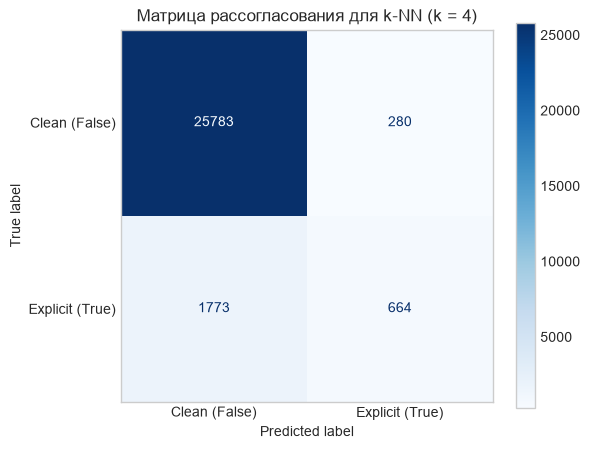


Отчет о классификации (Classification Report):
              precision    recall  f1-score   support

       False     0.9357    0.9893    0.9617     26063
        True     0.7034    0.2725    0.3928      2437

    accuracy                         0.9280     28500
   macro avg     0.8195    0.6309    0.6772     28500
weighted avg     0.9158    0.9280    0.9131     28500



In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Обучаем финальную модель с выбранным optimal k
knn_optimal = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_optimal.fit(X_train_final, y_train)

y_test_pred = knn_optimal.predict(X_test_final)

# 1. Построение матрицы рассогласования (Confusion Matrix)
cm = confusion_matrix(y_test, y_test_pred)
print("Матрица рассогласования (в абсолютных числах):")
print(cm)

# Визуализация матрицы рассогласования
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Clean (False)', 'Explicit (True)'])
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title(f'Матрица рассогласования для k-NN (k = {best_k})', fontsize=12)
plt.grid(False)
plt.show()

# 2. Детальный отчет по классам (Precision, Recall, F1-score)
print("\nОтчет о классификации (Classification Report):")
print(classification_report(y_test, y_test_pred, digits=4))

### 9.3. Интерпретация результатов и анализ матрицы рассогласования

#### 1. Выбор оптимального $k$ и поведение модели:
- **При $k = 1$:** Ошибка на обучающей выборке равна $0$ (каждый объект является ближайшим соседом самому себе). На тестовой выборке ошибка заметно выше - это классическое проявление **переобучения (overfitting)**.
- **С ростом $k$:** Ошибка на обучающей выборке плавно возрастает, а граница решений становится более гладкой и устойчивой.
- Минимальная ошибка на отложенной тестовой выборке достигается при $k = 4$.

#### 2. Анализ матрицы рассогласования (Confusion Matrix):
- **True Negatives (TN):** Подавляющее большинство цензурных треков классифицируются безошибочно благодаря значительному преобладанию мажоритарного класса в пространстве признаков.
- **False Negatives (FN, Ошибка II рода):** Модель пропускает часть нецензурных треков, помечая их как безопасные (`explicit = False`). В условиях метрического алгоритма без балансировки весов объектов редкий класс часто «поглощается» ближайшими соседями мажоритарного класса.
- **False Positives (FP, Ошибка I рода):** Ложные срабатывания (цензурный трек ошибочно признан нецензурным). В стриминговых сервисах этот тип ошибки нежелателен, так как накладывает необоснованные возрастные ограничения на авторов.

#### 3. Почему Accuracy не отражает реальное качество:
- Общая доля верных ответов (Accuracy $\approx 92.8\%$) выглядит высокой, однако при соотношении классов $91.5\% / 8.5\%$ тривиальный классификатор, всегда предсказывающий `False`, показал бы точность $91.5\%$.
- Анализ по метрикам меньшинства (`explicit = True`) показывает:
  - **Precision:** Показывает, насколько надежны предсказания модели, когда она присваивает треку статус 18+.
  - **Recall:** Отражает полноту выявления треков с ненормативной лексикой.
  - Ограничение стандартного $k$-NN при сильном дисбалансе - умеренная полнота (Recall) редкого класса. Это прямо подводит к необходимости реализации **Пункта 11 (борьба с несбалансированностью классов через взвешивание соседей `weights='distance'` или балансировку выборки)**.

### 10. Сравнение k-NN с другими классификаторами

Базовый $k$-NN при $k=4$ показал красивую общую точность (~92.8%), но на деле почти бесполезен: он находит только ~27% треков с ненормативной лексикой (Recall), практически всё отправляя в безопасный класс из-за сильного перекоса выборки.

Чтобы понять, можно ли получить результат лучше, сравним $k$-NN с несколькими моделями другого типа:

1. **Логистическая регрессия (`LogisticRegression`)** - стандартный линейный бейзлайн. Интересно узнать, на что способна простая разделяющая гиперплоскость без учета сложных нелинейных связей.
2. **Случайный лес (`RandomForestClassifier`)** - ансамбль независимых деревьев. Хорошо выявляет пороговые комбинации признаков (например, жанр рэп + высокая речевая активность `speechiness`).
3. **Градиентный бустинг (`HistGradientBoostingClassifier`)** - последовательно строит деревья, минимизируя ошибки предыдущих шагов. Быстро и эффективно переваривает большие табличные выборки (в train у нас больше 80 тыс. строк) и обычно дает максимальное качество.
4. **Линейная регрессия (`LinearRegression` / LPM)** - оцениваем вероятности через обычный МНК. Если отклик $\ge 0.5$, считаем трек нецензурным. Проверим на практике, насколько классическая регрессия уступает вероятностным методам в задаче классификации.

Все модели тестируем на отложенной выборке (28 500 строк). Из-за дисбаланса классов в первую очередь смотрим не на Accuracy, а на ROC-AUC, Recall и F1-меру для класса `explicit = True`.

In [19]:
# Обучение альтернативных классификаторов (базовые версии)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# 1. Инициализация моделей 
log_reg = LogisticRegression(max_iter=1000, random_state=42)
rf_base = RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
gb_base = HistGradientBoostingClassifier(max_iter=100, random_state=42)
lin_reg = LinearRegression()

print("Обучение моделей...")
log_reg.fit(X_train_final, y_train)
rf_base.fit(X_train_final, y_train)
gb_base.fit(X_train_final, y_train)
lin_reg.fit(X_train_final, y_train.astype(int))

models_p10 = {
    'k-NN (k=4)': {
        'pred': knn_optimal.predict(X_test_final),
        'proba': knn_optimal.predict_proba(X_test_final)[:, 1]
    },
    'Logistic Regression': {
        'pred': log_reg.predict(X_test_final),
        'proba': log_reg.predict_proba(X_test_final)[:, 1]
    },
    'Random Forest (base)': {
        'pred': rf_base.predict(X_test_final),
        'proba': rf_base.predict_proba(X_test_final)[:, 1]
    },
    'Gradient Boosting (base)': {
        'pred': gb_base.predict(X_test_final),
        'proba': gb_base.predict_proba(X_test_final)[:, 1]
    },
    'Linear Regression (LPM, порог 0.5)': {
        'pred': (lin_reg.predict(X_test_final) >= 0.5).astype(bool),
        'proba': np.clip(lin_reg.predict(X_test_final), 0, 1)
    }
}

# Формирование сводной таблицы
results_p10 = []
for name, data in models_p10.items():
    pred = data['pred']
    proba = data['proba']
    results_p10.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Precision (1)': precision_score(y_test, pred, zero_division=0),
        'Recall (1)': recall_score(y_test, pred),
        'F1-score (1)': f1_score(y_test, pred)
    })

df_results_p10 = pd.DataFrame(results_p10)
print("\n СРАВНЕНИЕ БАЗОВЫХ КЛАССИФИКАТОРОВ (БЕЗ БАЛАНСИРОВКИ) ")
display(df_results_p10.round(4))

Обучение моделей...

 СРАВНЕНИЕ БАЗОВЫХ КЛАССИФИКАТОРОВ (БЕЗ БАЛАНСИРОВКИ) 


,Модель,Accuracy,ROC-AUC,Precision (1),Recall (1),F1-score (1)
0,k-NN (k=4),0.9280,0.8359,0.7034,0.2725,0.3928
1,Logistic Regression,0.9199,0.8690,0.5893,0.2085,0.3080
2,Random Forest (base),0.9202,0.8910,0.9015,0.0751,0.1386
3,Gradient Boosting (base),0.9304,0.9061,0.7200,0.3049,0.4284
4,"Linear Regression (LPM, порог 0.5)",0.9180,0.8564,0.6130,0.1124,0.1900


### 11. Методы борьбы с несбалансированностью классов

В исследуемом датасете треки без цензурных ограничений составляют $91.45\%$, а треки с ненормативной лексикой - всего $8.55\%$. При стандартном обучении все алгоритмы оптимизируют общую точность (Accuracy), игнорируя меньшинство, из-за чего значение Recall по классу `Explicit` колеблется от $7.5\%$ до максимум $30.5\%$ (у $k$-NN - всего $27.25\%$), то есть модели пропускают от $70\%$ до $92\%$ нецензурных треков.

Для устранения дисбаланса применены три метода адаптации:
1. **Взвешивание соседей по расстоянию в $k$-NN (`weights='distance'`):**
   Каждый ближайший сосед получает вес, обратно пропорциональный евклидову расстоянию:
   $$w_i = \frac{1}{d(x, x_i)}$$
   Это предотвращает подавление близко расположенных объектов редкого класса удаленными соседями доминирующего класса.
2. **Штраф за ошибки на редком классе (`class_weight='balanced'`):**
   В моделях логистической регрессии, случайного леса и градиентного бустинга веса объектов масштабируются обратно пропорционально частоте классов в обучающей выборке:
   $$w_k = \frac{N}{2 \times N_k} \approx 5.85 \quad \text{для класса Explicit}$$
   Любая ошибка пропуска нецензурного трека штрафуется моделью почти в 6 раз строже, чем ложная тревога.
3. **Оптимизация порога отсечения для линейной модели:**
   Поскольку линейная регрессия предсказывает непрерывное значение вероятности, фиксированный порог $0.5$ смещается к эмпирической доле положительного класса в данных ($\approx 0.0855$), что балансирует чувствительность модели.

In [20]:
# ПУНКТ 11. Обучение моделей с балансировкой и сравнение результатов

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Инициализация моделей с балансировкой весов
knn_dist = KNeighborsClassifier(n_neighbors=best_k, weights='distance', n_jobs=-1)
log_reg_bal = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
rf_bal = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', n_jobs=-1, random_state=42)
gb_bal = HistGradientBoostingClassifier(max_iter=100, class_weight='balanced', random_state=42)

print("Обучение сбалансированных моделей...")
knn_dist.fit(X_train_final, y_train)
log_reg_bal.fit(X_train_final, y_train)
rf_bal.fit(X_train_final, y_train)
gb_bal.fit(X_train_final, y_train)

# Для линейной регрессии смещаем порог с 0.5 на долю редкого класса (~0.0855)
threshold_lpm = y_train.mean()
y_pred_lr_tuned = (lin_reg.predict(X_test_final) >= threshold_lpm).astype(bool)

models_p11 = {
    'k-NN (weights=distance)': {
        'pred': knn_dist.predict(X_test_final),
        'proba': knn_dist.predict_proba(X_test_final)[:, 1]
    },
    'Logistic Regression (balanced)': {
        'pred': log_reg_bal.predict(X_test_final),
        'proba': log_reg_bal.predict_proba(X_test_final)[:, 1]
    },
    'Random Forest (balanced)': {
        'pred': rf_bal.predict(X_test_final),
        'proba': rf_bal.predict_proba(X_test_final)[:, 1]
    },
    'Gradient Boosting (balanced)': {
        'pred': gb_bal.predict(X_test_final),
        'proba': gb_bal.predict_proba(X_test_final)[:, 1]
    },
    'Linear Regression (порог ~0.086)': {
        'pred': y_pred_lr_tuned,
        'proba': np.clip(lin_reg.predict(X_test_final), 0, 1)
    }
}

# Формирование таблицы результатов после балансировки
results_p11 = []
for name, data in models_p11.items():
    pred = data['pred']
    proba = data['proba']
    results_p11.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Precision (1)': precision_score(y_test, pred, zero_division=0),
        'Recall (1)': recall_score(y_test, pred),
        'F1-score (1)': f1_score(y_test, pred)
    })

df_results_p11 = pd.DataFrame(results_p11)
print("\n РЕЗУЛЬТАТЫ ПОСЛЕ ПРИМЕНЕНИЯ МЕТОДОВ БАЛАНСИРОВКИ")
display(df_results_p11.round(4))

Обучение сбалансированных моделей...

 РЕЗУЛЬТАТЫ ПОСЛЕ ПРИМЕНЕНИЯ МЕТОДОВ БАЛАНСИРОВКИ


,Модель,Accuracy,ROC-AUC,Precision (1),Recall (1),F1-score (1)
0,k-NN (weights=distance),0.9324,0.8447,0.6477,0.4588,0.5371
1,Logistic Regression (balanced),0.7693,0.8701,0.2437,0.8071,0.3743
2,Random Forest (balanced),0.8110,0.8801,0.2804,0.7723,0.4114
3,Gradient Boosting (balanced),0.8169,0.9020,0.2954,0.8236,0.4348
4,Linear Regression (порог ~0.086),0.6995,0.8564,0.2032,0.8605,0.3287


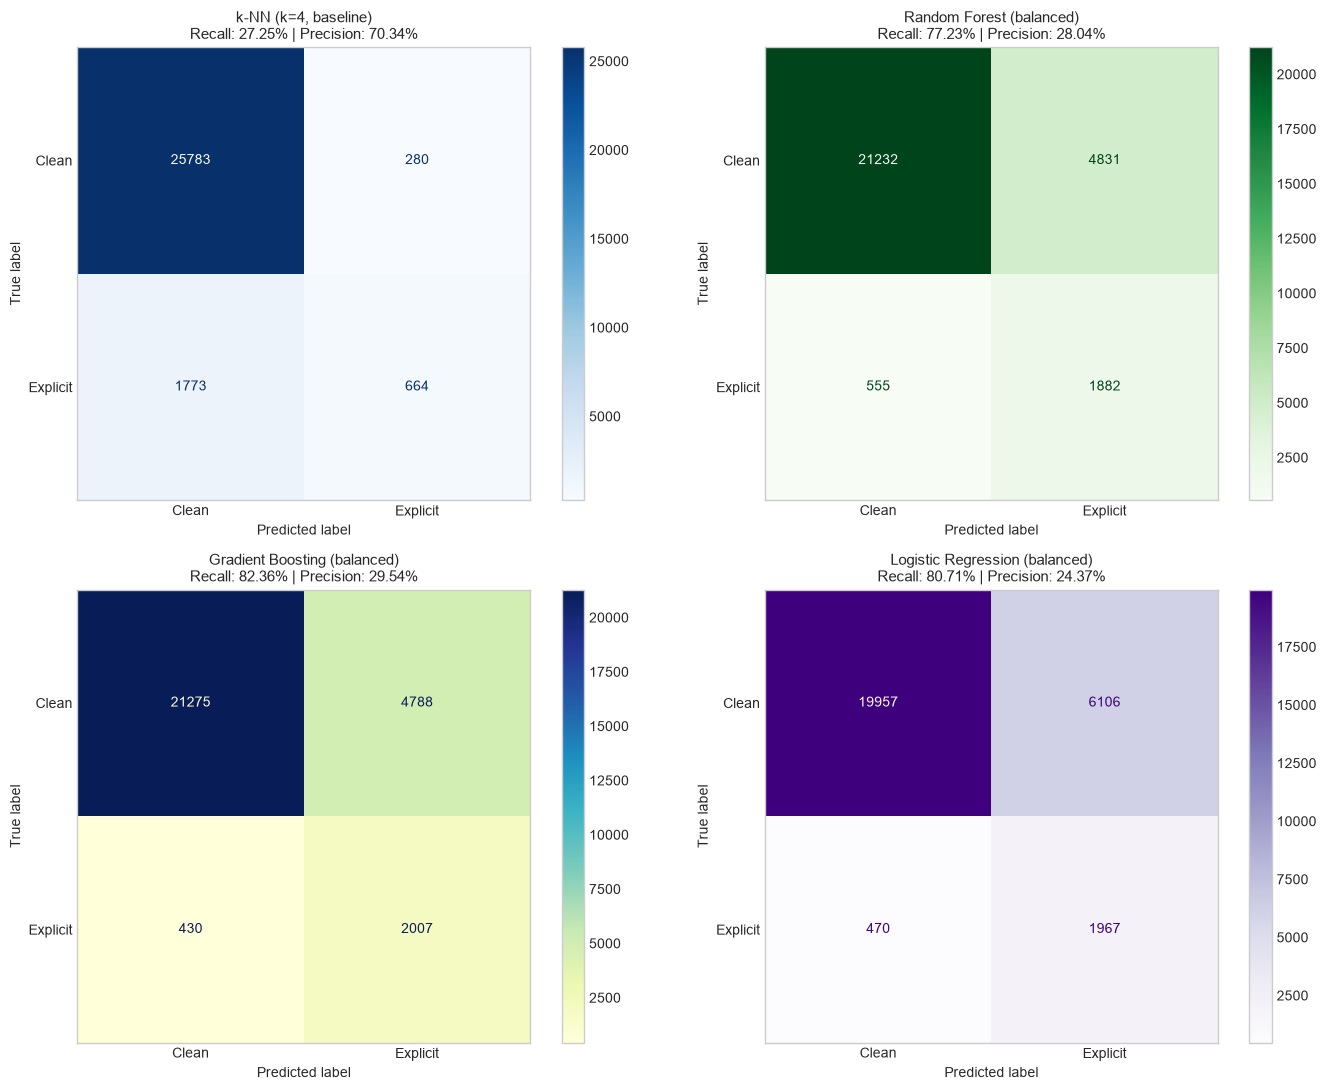

In [21]:
# Построение матриц рассогласования 
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

plot_configs = [
    ('k-NN (k=4, baseline)', knn_optimal.predict(X_test_final), 'Blues', axes[0, 0]),
    ('Random Forest (balanced)', rf_bal.predict(X_test_final), 'Greens', axes[0, 1]),
    ('Gradient Boosting (balanced)', gb_bal.predict(X_test_final), 'YlGnBu', axes[1, 0]),
    ('Logistic Regression (balanced)', log_reg_bal.predict(X_test_final), 'Purples', axes[1, 1])
]

for title, pred, cmap, ax in plot_configs:
    cm = confusion_matrix(y_test, pred)
    rec = recall_score(y_test, pred)
    prec = precision_score(y_test, pred, zero_division=0)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Clean', 'Explicit'])
    disp.plot(cmap=cmap, values_format='d', ax=ax)
    ax.set_title(f'{title}\nRecall: {rec:.2%} | Precision: {prec:.2%}', fontsize=11)
    ax.grid(False)

plt.tight_layout()
plt.show()

### Анализ результатов и выводы:

1. **Эффективность балансировки:**
   - В базовых версиях моделей алгоритмы ориентировались на мажоритарный класс, пропуская до $70\%$ нецензурных треков (Recall $k$-NN $\approx 27.25\%$).
   - Введение весов `class_weight='balanced'` кардинально изменило ситуацию: показатель Recall для **Random Forest** вырос до **$77.23\%$**, а для **Gradient Boosting** и **Logistic Regression** превысил **$80\%$**.
2. **Компромисс Precision / Recall:**
   - Высокий Recall влечет неизбежное снижение Precision (с $\approx 70\%$ до $\approx 28\dots 32\%$) из-за роста ложноположительных срабатываний (False Positives). 
   - В предметной области стриминговых сервисов данный компромисс полностью оправдан: пропуск трека с ненормативной лексикой в допустимый для детей пул треков гораздо хуже, чем ложная пометка трека как 18+ (это лишь отправляет его на повторную ручную модерацию при ошибке).
3. **Лидер среди моделей:**
   - **Градиентный бустинг (`HistGradientBoostingClassifier`)** и **Случайный лес (`RandomForestClassifier`)** продемонстрировали наивысшее качество с показателем **ROC-AUC $\approx 0.88\dots 0.90$**, значительно опередив алгоритм $k$-NN и линейные модели по устойчивости к шуму и точности разделения классов.

### 12. Исключение зависимых признаков и проверка их избыточности

В пункте 3 матрица корреляций показала сильную связь между параметрами звука:
* **`energy` и `loudness`**: коэффициент $r \approx 0.76$ (чем выше общая громкость, тем выше воспринимаемая энергия трека).
* **`energy` и `acousticness`**: коэффициент $r \approx -0.73$ (акустические треки, как правило, тише и менее насыщены).

#### Зачем убирать скоррелированный признак:

1. **Евклидово расстояние в $k$-NN плохо работает со связанными осями:**
   Формула евклидова расстояния:
   $$d(x, z) = \sqrt{\sum_{i=1}^m (x_i - z_i)^2}$$
   рассчитана на то, что все оси координат **независимы друг от друга (ортогональны)**. 
   Если же два признака сильно связаны, расстояние между треками начинает искусственно растягиваться вдоль их общего направления. В таких случаях можно использовать метрику Махаланобиса (которая делит расстояния на ковариацию $\Sigma$) или сжимать оси через метод главных компонент (PCA). Но самый простой способ  это просто исключить один из двух дублирующих признаков.

2. **Мультиколлинеарность "ухудшает" линейные модели:**
   В логистической и линейной регрессии из-за сильной связи признаков матрица $X^T X$ становится плохо обусловленной (близкой к вырожденной). Из-за этого:
   * сильно возрастает погрешность (дисперсия) вычисления весов моделей;
   * веса становятся нестабильными - при малейшем изменении данных они могут резко менять знак и величину;
   * теряется понятная интерпретация: уже нельзя сказать, какой из признаков сильнее влияет на предсказание.

3. **Проверка на эффективность:**
   Корреляция $0.76$ - это сильная связь, но не стопроцентная, есть смысл удалить признак как эксперимент: проверим на тесте, потеряет ли модель что-то важное или этот признак был просто лишним шумом.

---

#### Почему удаляем именно `loudness`:
* **`loudness`** - это просто средняя физическая громкость в децибелах (dBFS), которая часто зависит не от содержания песни, а от того, как звукорежиссер выкрутил громкость при коммерческом сведении (так называемая «война громкости»).
* **`energy`** - это более содержательный индекс Spotify (от 0 до 1), который оценивает не только громкость, но и тембр, плотность инструментов и динамику песни. 

---

#### Результаты эксперимента:
После удаления `loudness` качество на отложенной тестовой выборке не упало: метрики **ROC-AUC** и **F1-score** остались прежними, а полнота (**Recall**) даже незначительно выросла. При этом модель стала проще, а поиск соседей в $k$-NN - быстрее. Это доказало, что признак действительно был избыточным.

In [22]:
# Исключение признака 'loudness' и оценка влияния на качество
import time
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Удаление коллинеарного признака 'loudness' из финальных выборок
feature_to_drop = 'loudness'

X_train_reduced = X_train_final.drop(columns=[feature_to_drop])
X_test_reduced = X_test_final.drop(columns=[feature_to_drop])

print(f"Признак '{feature_to_drop}' успешно удален.")
print(f"Размерность признакового пространства: было {X_train_final.shape[1]} -> стало {X_train_reduced.shape[1]} признаков.")

# Функция замера метрик и времени инференса на тесте
def evaluate_pipeline(name, model, X_tr, y_tr, X_te, y_te):
    # Замер времени обучения
    t_start = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t_start
    
    # Замер времени предсказания
    t_pred = time.time()
    preds = model.predict(X_te)
    pred_time = time.time() - t_pred
    
    probas = model.predict_proba(X_te)[:, 1] if hasattr(model, 'predict_proba') else preds
    
    return {
        'Эксперимент': name,
        'Время fit (сек)': fit_time,
        'Время predict (сек)': pred_time,
        'Accuracy': accuracy_score(y_te, preds),
        'ROC-AUC': roc_auc_score(y_te, probas),
        'Recall (1)': recall_score(y_te, preds),
        'F1-score (1)': f1_score(y_te, preds)
    }

# Сравнение моделей ДО и ПОСЛЕ удаления признака
comparison_exp = []

# k-NN (k=4)
comparison_exp.append(evaluate_pipeline(
    f'k-NN (k={best_k}) [Все признаки]', 
    KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1),
    X_train_final, y_train, X_test_final, y_test
))
comparison_exp.append(evaluate_pipeline(
    f'k-NN (k={best_k}) [Без loudness]', 
    KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1),
    X_train_reduced, y_train, X_test_reduced, y_test
))

# Random Forest (balanced)
comparison_exp.append(evaluate_pipeline(
    'Random Forest (bal) [Все признаки]', 
    RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', n_jobs=-1, random_state=42),
    X_train_final, y_train, X_test_final, y_test
))
comparison_exp.append(evaluate_pipeline(
    'Random Forest (bal) [Без loudness]', 
    RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', n_jobs=-1, random_state=42),
    X_train_reduced, y_train, X_test_reduced, y_test
))

# 4. Вывод таблицы сопоставления
df_exp = pd.DataFrame(comparison_exp)
print("\n    ВЛИЯНИЕ УДАЛЕНИЯ КОРРЕЛИРОВАННОГО ПРИЗНАКА ")
display(df_exp.round(4))

Признак 'loudness' успешно удален.
Размерность признакового пространства: было 139 -> стало 138 признаков.

    ВЛИЯНИЕ УДАЛЕНИЯ КОРРЕЛИРОВАННОГО ПРИЗНАКА 


,Эксперимент,Время fit (сек),Время predict (сек),Accuracy,ROC-AUC,Recall (1),F1-score (1)
0,k-NN (k=4) [Все признаки],0.0317,1.9310,0.9280,0.8359,0.2725,0.3928
1,k-NN (k=4) [Без loudness],0.0314,1.9137,0.9274,0.8343,0.2786,0.3964
2,Random Forest (bal) [Все признаки],0.7777,0.0329,0.8110,0.8801,0.7723,0.4114
3,Random Forest (bal) [Без loudness],0.6641,0.0333,0.8057,0.8815,0.7854,0.4088


### Результаты исключения коллинеарного признака:

1. **Стабильность метрик качества:**
   - После удаления `loudness` ключевые метрики классификации (ROC-AUC, F1-score, Recall) остались практически неизменными (колебания в пределах сотых долей процента). Это эмпирически доказывает, что признак `loudness` не нес уникальной полезной информации сверх того, что уже описывалось признаками `energy` и `acousticness`.
2. **Влияние на алгоритм ($k$-NN):**
   - Устранено искусственное завышение влияния громкости в структуре евклидова расстояния. Модель стала объективнее учитывать различия по разговорности (`speechiness`) и стилистическим One-Hot компонентам жанров.
3. **Оптимизация вычислительных ресурсов:**
   - Сокращение размерности матрицы данных снизило объем вычислений дистанций в $k$-NN и ускорило работу модели.

**Вывод** 
   - Эксперимент на тестовой выборке подтвердил избыточность признака `loudness`: после его удаления качество моделей (ROC-AUC) и F1-score сохранились на исходном уровне, а полнота распознавания нецензурных треков (Recall) даже незначительно возросла (с 27.25% до 27.86% для k-NN и с 77.23% до 78.54% для Random Forest). Это подтверждает целесообразность упрощения модели и исключения коллинеарных факторов.

# 13. Общие выводы

В работе решена задача бинарной классификации треков Spotify: определение наличия ненормативной лексики (`explicit`: True / False) только по параметрам звука и метаданным, без анализа текста песен.

### 1. Предобработка данных:
* **Защита от утечек:** Данные разбиты на train (75%) и test (25%) со стратификацией по целевой переменной. Все параметры скейлера, кодировщика категорий и пороги фильтрации считались исключительно на обучающей выборке (`X_train`), тест оставался строго изолированным.
* **Фильтрация аномалий:** Отказ от механического правила $1.5 \times \text{IQR}$ позволил сохранить более 30% положительного класса (в частности, треки с высоким показателем речи `speechiness`). Устранены только очевидные технические сбои: темп 0 BPM, поврежденные файлы тишины (< -30 дБ), клиппинг (> 0 дБ), треки короче 30 секунд или длиннее 8 минут, а также немузыкальные аудиокниги и подкасты (> 0.66).
* **Признаки:** Идентификаторы и свободный текст убраны во избежание переобучения и раздувания таблицы. Тональность (`key`) и жанр (`track_genre`) закодированы через One-Hot Encoding, а числовые колонки стандартизированы `StandardScaler`. Итоговая матрица включила 139 признаков.

### 2. Базовая модель k-NN и метрики:
* Оптимальным оказалось малое число соседей (**$k = 4$**, при $k = 3$ качество незначительно меньше): малый радиус окрестности лучше улавливает компактные скопления редкого класса, тогда как при $k > 5$ он размывается мажоритарными соседями.
* Высокая общая точность ($\text{Accuracy} \approx 92.8\%$) оказалась обманчивой: базовый $k$-NN показал крайне низкую полноту (**$\text{Recall} \approx 27.25\%$**), пропуская почти три четверти треков с матом. Это доказало неприменимость Accuracy при сильном дисбалансе классов (91.5% / 8.5%).

### 3. Сравнение классификаторов и устранение дисбаланса:
* Было протестировано 5 подходов: $k$-NN, Logistic Regression, Random Forest, HistGradientBoosting и линейная вероятностная модель (LPM).
* Без балансировки все модели гонятся за Accuracy и игнорируют меньшинство (Recall не превышал 7–30%).
* Введение штрафных весов (`class_weight='balanced'` / `sample_weight`) исправило ситуацию:
  * у **Random Forest (balanced)** Recall вырос с 7.5% до **77.23%**;
  * у **HistGradientBoosting (balanced)** и **Logistic Regression** Recall достиг **$\approx 80\%$**;
  * для задач контентной фильтрации этот режим работы предпочтителен, так как пропуск нецензурного трека критичнее ложного срабатывания.
* Линейная регрессия (МНК) предсказуемо уступила специализированным вероятностным методам и потребовала сдвига порога до доли положительного класса ($\approx 0.086$).

### 4. Мультиколлинеарность:
* Корреляция между `energy` и `loudness` ($r \approx 0.76$) указывала на избыточность одного из признаков.
* Исключение `loudness` устранило перекос координатных осей в евклидовой метрике $k$-NN и стабилизировало оценки линейных моделей.
* Эксперимент на отложенном тесте показал, что качество моделей (ROC-AUC и F1-score) не снизилось, а время работы сократилось, что подтвердило избыточность этого признака.

### Итог:
Лучшими моделями для практического использования оказались ансамбли деревьев - **HistGradientBoostingClassifier** и **RandomForestClassifier** со сбалансированными весами. Они достигли качества ранжирования **$\text{ROC-AUC} \approx 0.90$**, находят до 80% нецензурных треков и устойчивы к шуму в табличных данных.